# Question 11 L1 L2 and Elastic Net Regularization on World Bank Data

**Aim:** Implement and compare L1, L2, and Elastic Net regularization for predicting real GDP per capita from macroeconomic indicators.

The experiment uses a saved 2010–2023 World Bank World Development Indicators panel. Performance is measured on economies never seen during training.

## Problem Statement

Economic indicators are correlated, use different scales, and contain missing observations. Predict the natural logarithm of GDP per capita using linear models, then evaluate how L1, L2, and Elastic Net penalties affect unseen-economy accuracy, coefficient shrinkage, and feature selection. Coefficients are predictive associations, not causal estimates.

## Algorithm

1. Retain country-year rows with a GDP target and at least six observed predictors.
2. Log-transform GDP per capita to reduce right skew.
3. Split entire economies into 80% training and 20% testing groups.
4. Median-impute and standardize inside each training fold.
5. Select regularization parameters with five-fold grouped cross-validation.
6. Evaluate Linear Regression, Lasso, Ridge, and Elastic Net on held-out economies.
7. Modify alpha and observe validation error, shrinkage, and sparsity.

## Program

### Imports and Reproducibility

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42
ROOT = Path.cwd() if (Path.cwd() / "notebooks").exists() else Path.cwd().parent
DATA_PATH = ROOT / "data" / "world_bank_macro_2010_2023.csv"
FIGURE_DIR = ROOT / "results" / "figures"
METRIC_DIR = ROOT / "results" / "metrics"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
METRIC_DIR.mkdir(parents=True, exist_ok=True)

FEATURES = [
    "trade_pct_gdp", "gross_capital_formation_pct_gdp", "inflation_consumer_pct",
    "unemployment_pct", "fdi_net_inflows_pct_gdp", "government_consumption_pct_gdp",
    "industry_value_added_pct_gdp", "urban_population_pct", "population_growth_pct",
]
FEATURE_LABELS = {
    "trade_pct_gdp": "Trade (% GDP)",
    "gross_capital_formation_pct_gdp": "Capital formation (% GDP)",
    "inflation_consumer_pct": "Inflation (%)",
    "unemployment_pct": "Unemployment (%)",
    "fdi_net_inflows_pct_gdp": "FDI inflows (% GDP)",
    "government_consumption_pct_gdp": "Government consumption (% GDP)",
    "industry_value_added_pct_gdp": "Industry value added (% GDP)",
    "urban_population_pct": "Urban population (%)",
    "population_growth_pct": "Population growth (%)",
}
plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 30)

from sklearn.impute import SimpleImputer
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, GroupKFold, GroupShuffleSplit, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

### Dataset and Data Dictionary

Each row is one economy-year. The target is GDP per capita in constant 2015 US dollars. Predictors cover trade, investment, inflation, unemployment, FDI, government consumption, industry, urbanization, and population growth. Country, region, and income group are descriptive metadata rather than predictors.

,Value
Country-year rows,3283.000000
Economies,241.000000
First year,2010.000000
Last year,2023.000000
Median GDP per capita,5634.164827


,Missing percent
urban_population_pct,0.0
population_growth_pct,0.0
industry_value_added_pct_gdp,1.2
fdi_net_inflows_pct_gdp,2.3
unemployment_pct,4.9
inflation_consumer_pct,5.2
trade_pct_gdp,8.8
government_consumption_pct_gdp,9.1
gross_capital_formation_pct_gdp,9.3


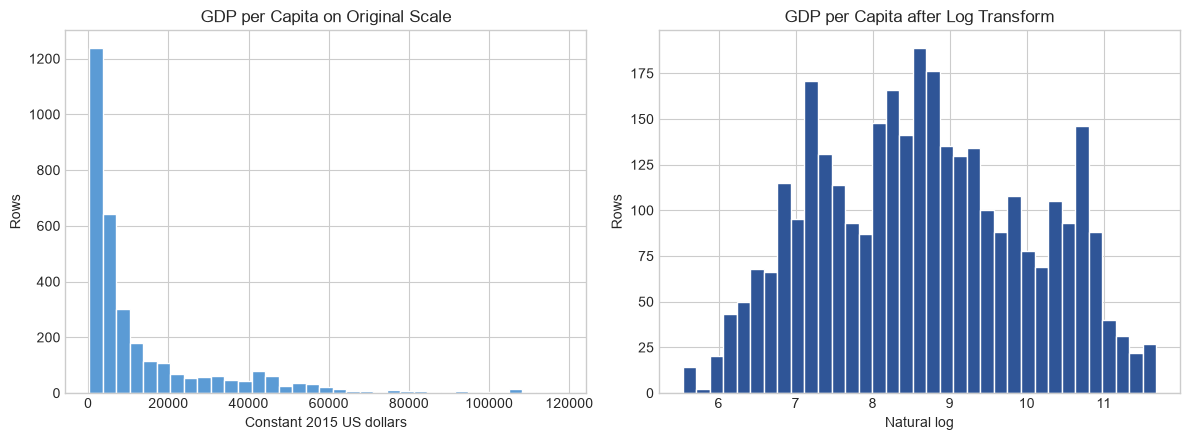

In [2]:
raw = pd.read_csv(DATA_PATH)
target = "gdp_per_capita_constant_2015_usd"
data = raw.loc[raw[target].notna() & (raw[FEATURES].notna().sum(axis=1) >= 6)].copy()
data["log_gdp_per_capita"] = np.log(data[target])

summary_table = pd.DataFrame({"Value": [
    len(data), data.country_code.nunique(), int(data.year.min()), int(data.year.max()),
    data[target].median(),
]}, index=["Country-year rows", "Economies", "First year", "Last year", "Median GDP per capita"])
display(summary_table)
display((data[FEATURES].isna().mean() * 100).sort_values().rename("Missing percent").round(1).to_frame())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(data[target], bins=35, color="#5B9BD5", edgecolor="white")
axes[0].set(title="GDP per Capita on Original Scale", xlabel="Constant 2015 US dollars", ylabel="Rows")
axes[1].hist(data.log_gdp_per_capita, bins=35, color="#2F5597", edgecolor="white")
axes[1].set(title="GDP per Capita after Log Transform", xlabel="Natural log", ylabel="Rows")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "q11_world_bank_target_distribution.png", dpi=180, bbox_inches="tight")
plt.show()

### Key Parameters and Leakage-Safe Split

In [3]:
X, y, groups = data[FEATURES], data.log_gdp_per_capita, data.country_code
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train, groups_test = groups.iloc[train_idx], groups.iloc[test_idx]
train_countries, test_countries = set(groups_train), set(groups_test)
assert train_countries.isdisjoint(test_countries)

display(pd.DataFrame({
    "Training": [len(X_train), len(train_countries)],
    "Testing": [len(X_test), len(test_countries)],
}, index=["Rows", "Distinct economies"]))
print("Country overlap:", len(train_countries & test_countries))

,Training,Testing
Rows,2635,648
Distinct economies,192,49


Country overlap: 0


### Core Algorithm and Parameter Selection

All preprocessing remains inside each pipeline. Test values therefore cannot influence imputation, scaling, or parameter selection.

In [4]:
alpha_grid = np.logspace(-4, 2, 25)
cv = GroupKFold(n_splits=5)
specifications = {
    "Linear Regression": (LinearRegression(), {}),
    "Lasso L1": (Lasso(max_iter=100_000), {"model__alpha": alpha_grid}),
    "Ridge L2": (Ridge(), {"model__alpha": alpha_grid}),
    "Elastic Net": (ElasticNet(max_iter=100_000), {
        "model__alpha": alpha_grid, "model__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9]
    }),
}

models, selection_rows = {}, []
for name, (estimator, grid) in specifications.items():
    pipeline = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("model", estimator),
    ])
    search = GridSearchCV(pipeline, grid, scoring="neg_root_mean_squared_error", cv=cv, n_jobs=-1)
    search.fit(X_train, y_train, groups=groups_train)
    models[name] = search.best_estimator_
    selection_rows.append({"Model": name, "Best parameters": search.best_params_ or "None",
                           "Mean CV log RMSE": -search.best_score_})

selection = pd.DataFrame(selection_rows).set_index("Model")
display(selection)

,Best parameters,Mean CV log RMSE
Model,,
Linear Regression,None,0.913267
Lasso L1,{'model__alpha': 0.01778279410038923},0.911828
Ridge L2,{'model__alpha': 100.0},0.912179
Elastic Net,"{'model__alpha': 0.03162277660168379, 'model__...",0.911499


## Output and Analysis

### Held-Out Economy Results

In [5]:
rows, predictions, coefficient_values = [], {}, {}
for name, pipeline in models.items():
    pred_log = pipeline.predict(X_test)
    actual_usd, pred_usd = np.exp(y_test.to_numpy()), np.exp(pred_log)
    coef = pipeline.named_steps["model"].coef_
    predictions[name], coefficient_values[name] = pred_log, coef
    rows.append({
        "Model": name,
        "Test log RMSE": mean_squared_error(y_test, pred_log) ** 0.5,
        "Test log MAE": mean_absolute_error(y_test, pred_log),
        "Test R2": r2_score(y_test, pred_log),
        "Median absolute percentage error": np.median(np.abs(actual_usd - pred_usd) / actual_usd),
        "Nonzero coefficients": np.count_nonzero(np.abs(coef) > 1e-8),
        "Coefficient L1 norm": np.abs(coef).sum(),
        "Coefficient L2 norm": np.linalg.norm(coef),
    })
results = pd.DataFrame(rows).set_index("Model").sort_values("Test log RMSE")
display(results.round(4))
best_model = results.index[0]
print(f"Lowest held-out log RMSE: {best_model} ({results.iloc[0]['Test log RMSE']:.4f})")

,Test log RMSE,Test log MAE,Test R2,Median absolute percentage error,Nonzero coefficients,Coefficient L1 norm,Coefficient L2 norm
Model,,,,,,,
Linear Regression,0.7606,0.5780,0.6537,0.4696,9,1.7253,0.9524
Elastic Net,0.7623,0.5772,0.6521,0.4604,9,1.6256,0.9234
Ridge L2,0.7623,0.5790,0.6521,0.4603,9,1.6834,0.9218
Lasso L1,0.7623,0.5755,0.6521,0.4675,8,1.5883,0.9321


Lowest held-out log RMSE: Linear Regression (0.7606)


### Coefficient Shrinkage and Prediction Diagnostics

,Linear Regression,Lasso L1,Ridge L2,Elastic Net
Trade (% GDP),0.2376,0.2262,0.2380,0.2326
Capital formation (% GDP),0.0126,0.0006,0.0088,0.0040
Inflation (%),-0.1040,-0.0926,-0.1019,-0.0968
Unemployment (%),-0.0966,-0.0752,-0.0909,-0.0820
FDI inflows (% GDP),0.0123,0.0000,0.0140,0.0034
Government consumption (% GDP),0.0459,0.0303,0.0491,0.0395
Industry value added (% GDP),0.0651,0.0411,0.0666,0.0533
Urban population (%),0.8596,0.8536,0.8279,0.8376
Population growth (%),-0.2916,-0.2688,-0.2861,-0.2764


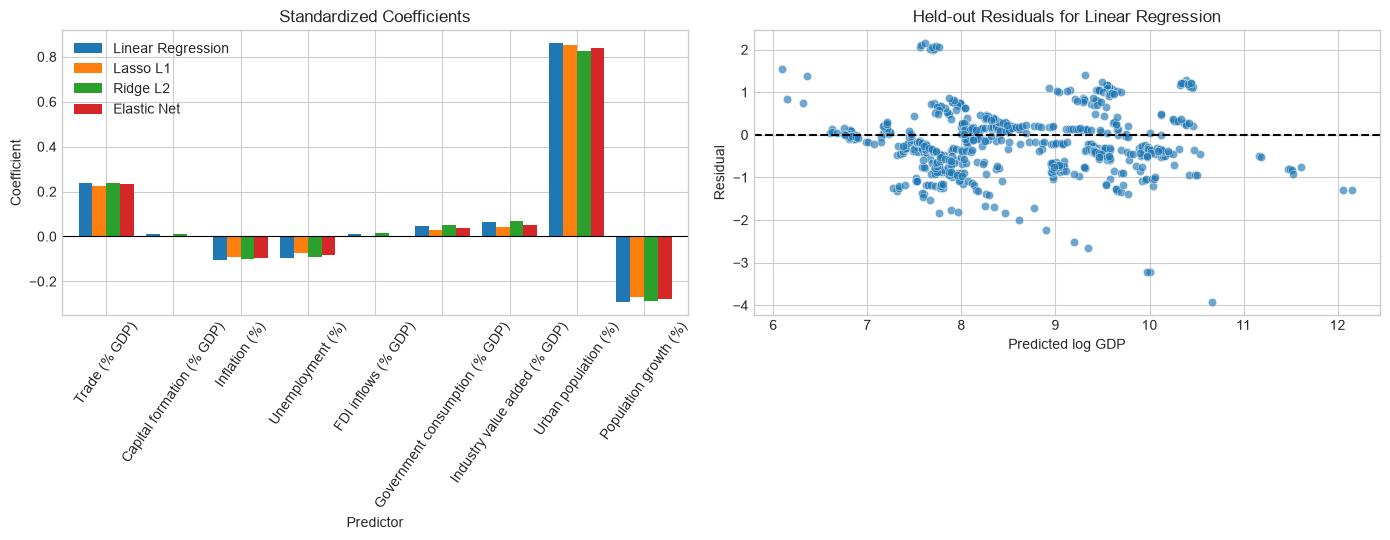

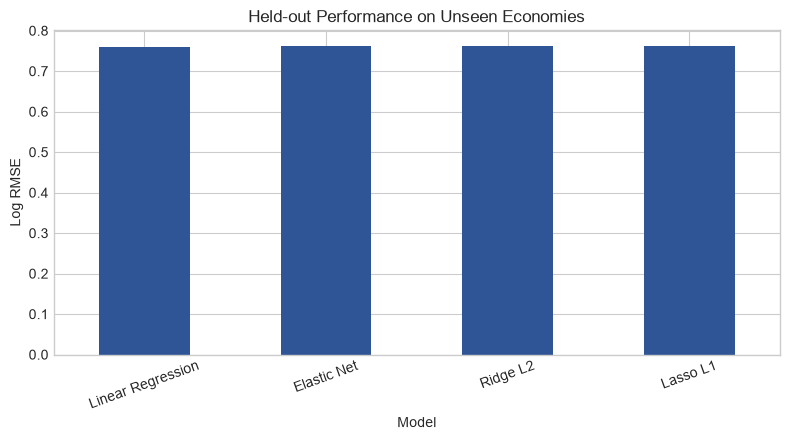

In [6]:
coefficients = pd.DataFrame(coefficient_values, index=[FEATURE_LABELS[x] for x in FEATURES])
display(coefficients.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
coefficients.plot(kind="bar", ax=axes[0], width=0.82)
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set(title="Standardized Coefficients", xlabel="Predictor", ylabel="Coefficient")
axes[0].tick_params(axis="x", rotation=55)
residuals = y_test.to_numpy() - predictions[best_model]
axes[1].scatter(predictions[best_model], residuals, alpha=0.65, edgecolor="white", linewidth=0.4)
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set(title=f"Held-out Residuals for {best_model}", xlabel="Predicted log GDP", ylabel="Residual")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "q11_regularization_coefficients_residuals.png", dpi=180, bbox_inches="tight")
plt.show()

ax = results["Test log RMSE"].sort_values().plot(kind="bar", figsize=(8, 4.5), color="#2F5597")
ax.set(title="Held-out Performance on Unseen Economies", ylabel="Log RMSE", xlabel="Model")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "q11_regularization_model_comparison.png", dpi=180, bbox_inches="tight")
plt.show()

## Parameter Modification

Alpha controls penalty strength. Each value uses the same split and grouped folds. Validation RMSE measures generalization, coefficient norm measures shrinkage, and the nonzero count measures sparsity.

,Method,Alpha,Mean CV log RMSE,CV standard deviation,Coefficient L2 norm,Nonzero coefficients
38,Elastic Net,0.02512,0.91156,0.05018,0.92773,8
5,Lasso L1,0.01000,0.91195,0.05012,0.94099,9
31,Ridge L2,100.00000,0.91218,0.04754,0.92177,9


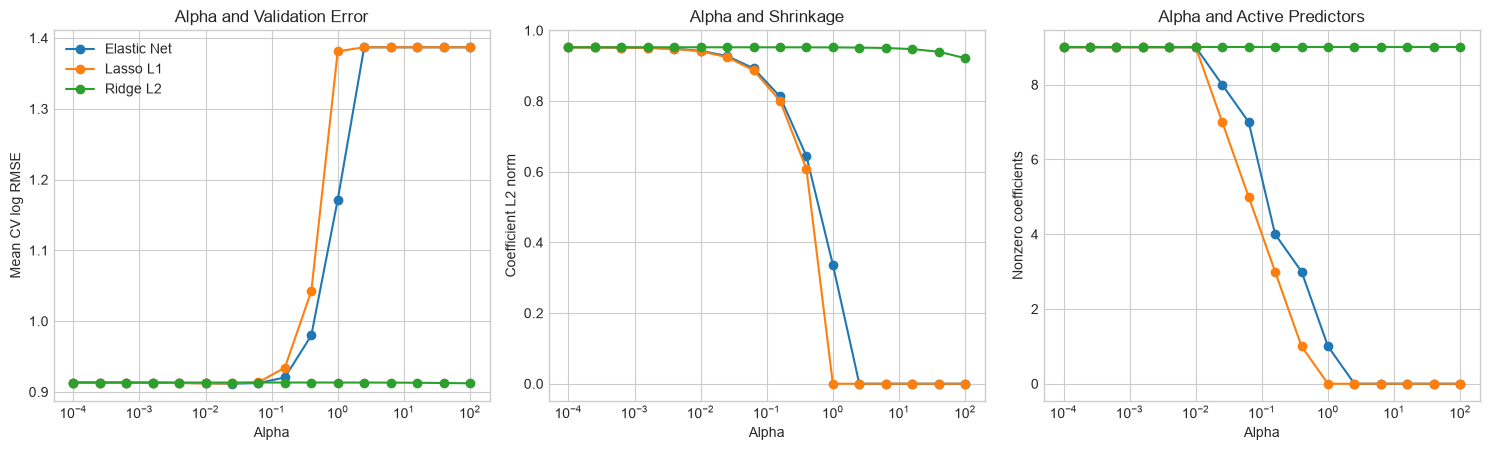

In [7]:
sensitivity_rows = []
factories = {
    "Lasso L1": lambda a: Lasso(alpha=a, max_iter=100_000),
    "Ridge L2": lambda a: Ridge(alpha=a),
    "Elastic Net": lambda a: ElasticNet(alpha=a, l1_ratio=0.5, max_iter=100_000),
}
for method, factory in factories.items():
    for alpha in np.logspace(-4, 2, 16):
        pipeline = Pipeline([("impute", SimpleImputer(strategy="median")),
                             ("scale", StandardScaler()), ("model", factory(alpha))])
        scores = -cross_val_score(pipeline, X_train, y_train, groups=groups_train, cv=cv,
                                  scoring="neg_root_mean_squared_error", n_jobs=-1)
        pipeline.fit(X_train, y_train)
        coef = pipeline.named_steps["model"].coef_
        sensitivity_rows.append({"Method": method, "Alpha": alpha,
            "Mean CV log RMSE": scores.mean(), "CV standard deviation": scores.std(),
            "Coefficient L2 norm": np.linalg.norm(coef),
            "Nonzero coefficients": np.count_nonzero(np.abs(coef) > 1e-8)})

sensitivity = pd.DataFrame(sensitivity_rows)
display(sensitivity.loc[sensitivity.groupby("Method")["Mean CV log RMSE"].idxmin()].round(5))
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for method, group in sensitivity.groupby("Method"):
    axes[0].semilogx(group.Alpha, group["Mean CV log RMSE"], marker="o", label=method)
    axes[1].semilogx(group.Alpha, group["Coefficient L2 norm"], marker="o", label=method)
    axes[2].semilogx(group.Alpha, group["Nonzero coefficients"], marker="o", label=method)
for axis, title, ylabel in zip(axes,
        ["Alpha and Validation Error", "Alpha and Shrinkage", "Alpha and Active Predictors"],
        ["Mean CV log RMSE", "Coefficient L2 norm", "Nonzero coefficients"]):
    axis.set(title=title, xlabel="Alpha", ylabel=ylabel)
axes[0].legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "q11_regularization_alpha_sensitivity.png", dpi=180, bbox_inches="tight")
plt.show()

## Conclusion and Saved Results

In [8]:
def scalar(value):
    return value.item() if isinstance(value, np.generic) else value

artifact = {"dataset": "World Bank World Development Indicators panel", "years": [2010, 2023],
    "rows": len(data), "economies": data.country_code.nunique(), "country_overlap": 0,
    "best_test_model": best_model, "models": {}}
for name, pipeline in models.items():
    estimator = pipeline.named_steps["model"]
    artifact["models"][name] = {
        "parameters": {k: scalar(v) for k, v in estimator.get_params().items() if k in {"alpha", "l1_ratio"}},
        **{k: scalar(v) for k, v in results.loc[name].items()},
    }
metric_path = METRIC_DIR / "q11_regularization_world_bank.json"
metric_path.write_text(json.dumps(artifact, indent=2) + "\n")

best_regularized = results.drop(index="Linear Regression")["Test log RMSE"].idxmin()
verb = "improved on" if results.loc[best_regularized, "Test log RMSE"] < results.loc["Linear Regression", "Test log RMSE"] else "did not improve on"
print(f"Conclusion: {best_regularized} was the strongest regularized model and {verb} the unregularized baseline. "
      f"Its held-out log RMSE was {results.loc[best_regularized, 'Test log RMSE']:.4f}, versus "
      f"{results.loc['Linear Regression', 'Test log RMSE']:.4f}. Stronger penalties reduced coefficient "
      "magnitudes, but excessive regularization raised validation error. The findings are predictive, not causal.")
print("Saved", metric_path.relative_to(ROOT))

Conclusion: Elastic Net was the strongest regularized model and did not improve on the unregularized baseline. Its held-out log RMSE was 0.7623, versus 0.7606. Stronger penalties reduced coefficient magnitudes, but excessive regularization raised validation error. The findings are predictive, not causal.
Saved results/metrics/q11_regularization_world_bank.json
